# MediShelf - Exploratory Data Analysis

## Notebook 02: Exploratory Data Analysis

This notebook examines the cleaned synthetic blood-demand dataset and pharmaceutical-sales dataset before forecasting. It focuses on data quality, distributions, time patterns, monthly aggregation, and preliminary stationarity checks.

**Important limitation:** the blood-demand data are synthetic. Any patterns identified here describe the supplied dataset and should not automatically be interpreted as evidence of real hospital demand patterns in Botswana.


In [19]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plt.rcParams["figure.figsize"] = (12, 5)


## 1. Load the cleaned datasets

The paths below assume this notebook is saved in the project's `notebooks` folder. The expected pharmaceutical filename is `pharma_sales_clean.csv`.


In [20]:
blood = pd.read_csv("../data/processed/blood_demand_clean.csv")
pharma = pd.read_csv("../data/processed/pharma_sales_clean.csv")

blood["Date"] = pd.to_datetime(blood["Date"], errors="coerce")
pharma["datum"] = pd.to_datetime(pharma["datum"], errors="coerce")

print("Blood dataset shape:", blood.shape)
print("Pharmaceutical dataset shape:", pharma.shape)

print("\nBlood date range:", blood["Date"].min(), "to", blood["Date"].max())
print("Pharmaceutical date range:", pharma["datum"].min(), "to", pharma["datum"].max())


Blood dataset shape: (1827, 10)
Pharmaceutical dataset shape: (2106, 12)

Blood date range: 2020-01-01 00:00:00 to 2024-12-31 00:00:00
Pharmaceutical date range: 2014-01-02 00:00:00 to 2019-10-08 00:00:00


## 2. Inspect structure and data quality

Check column names, data types, missing values, duplicated dates, and summary statistics. These checks help distinguish actual observations from helper columns and identify issues that could affect analysis.


In [21]:
display(blood.head())
display(pharma.head())

print("\nBlood data types and non-null counts:")
blood.info()

print("\nPharmaceutical data types and non-null counts:")
pharma.info()


,Date,DayOfWeek,Month,Population,Events,HistoricalBloodUsage,HospitalAdmissions,BloodDonorsAvailable,Temperature,PredictedBloodDemand
0,2020-01-01,2,1,171958,0,174,98,34,24.799194,258
1,2020-01-02,3,1,196867,0,187,71,55,21.590136,197
2,2020-01-03,4,1,181932,0,132,82,82,38.866004,182
3,2020-01-04,5,1,153694,0,74,88,88,30.089531,60
4,2020-01-05,6,1,169879,0,117,68,93,38.348783,117


,datum,Year,Month,Weekday Name,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
0,2014-01-02,2014,1,Thursday,0.0,3.67,3.4,32.40,7.0,0.0,0.0,2.0
1,2014-01-03,2014,1,Friday,8.0,4.00,4.4,50.60,16.0,0.0,20.0,4.0
2,2014-01-04,2014,1,Saturday,2.0,1.00,6.5,61.85,10.0,0.0,9.0,1.0
3,2014-01-05,2014,1,Sunday,4.0,3.00,7.0,41.10,8.0,0.0,3.0,0.0
4,2014-01-06,2014,1,Monday,5.0,1.00,4.5,21.70,16.0,2.0,6.0,2.0



Blood data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1827 entries, 0 to 1826
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Date                  1827 non-null   datetime64[ns]
 1   DayOfWeek             1827 non-null   int64         
 2   Month                 1827 non-null   int64         
 3   Population            1827 non-null   int64         
 4   Events                1827 non-null   int64         
 5   HistoricalBloodUsage  1827 non-null   int64         
 6   HospitalAdmissions    1827 non-null   int64         
 7   BloodDonorsAvailable  1827 non-null   int64         
 8   Temperature           1827 non-null   float64       
 9   PredictedBloodDemand  1827 non-null   int64         
dtypes: datetime64[ns](1), float64(1), int64(8)
memory usage: 142.9 KB

Pharmaceutical data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
R

In [22]:
print("Missing values — blood dataset")
display(blood.isna().sum().to_frame("Missing values"))

print("Missing values — pharmaceutical dataset")
display(pharma.isna().sum().to_frame("Missing values"))

print("Duplicate blood dates:", blood["Date"].duplicated().sum())
print("Duplicate pharmaceutical dates:", pharma["datum"].duplicated().sum())


Missing values — blood dataset


,Missing values
Date,0
DayOfWeek,0
Month,0
Population,0
Events,0
HistoricalBloodUsage,0
HospitalAdmissions,0
BloodDonorsAvailable,0
Temperature,0
PredictedBloodDemand,0


Missing values — pharmaceutical dataset


,Missing values
datum,0
Year,0
Month,0
Weekday Name,0
M01AB,0
M01AE,0
N02BA,0
N02BE,0
N05B,0
N05C,0


Duplicate blood dates: 0
Duplicate pharmaceutical dates: 0


> **About `PredictedBloodDemand`.** The synthetic source file ships a column
> named `PredictedBloodDemand`. It is a pre-computed demand estimate generated
> by whoever produced the synthetic dataset; we did not produce it, and using
> it would be circular — we would be evaluating one prediction with another.
> It is therefore **not** used as a target or as a feature anywhere in this
> project. The forecasting target for blood is `HistoricalBloodUsage`.
> Exogenous drivers (`HospitalAdmissions`, `Events`, `BloodDonorsAvailable`,
> `Temperature`) *are* tested in Notebook 04 via ARIMAX.

In [23]:
print("Blood numerical summary")
display(blood.describe().T)

print("Pharmaceutical numerical summary")
display(pharma.describe(include="all").T)


Blood numerical summary


,count,mean,min,25%,50%,75%,max,std
Date,1827,2022-07-02 00:00:00.000000256,2020-01-01 00:00:00,2021-04-01 12:00:00,2022-07-02 00:00:00,2023-10-01 12:00:00,2024-12-31 00:00:00,NaN
DayOfWeek,1827.0,3.0,0.0,1.0,3.0,5.0,6.0,2.000548
Month,1827.0,6.521073,1.0,4.0,7.0,10.0,12.0,3.450157
Population,1827.0,125902.013136,50126.0,87792.5,126323.0,164177.5,199859.0,43531.328946
Events,1827.0,0.047619,0.0,0.0,0.0,0.0,1.0,0.213017
HistoricalBloodUsage,1827.0,177.652436,50.0,117.0,180.0,238.0,299.0,71.575611
HospitalAdmissions,1827.0,64.894362,30.0,47.0,65.0,82.0,99.0,20.301757
BloodDonorsAvailable,1827.0,84.253421,20.0,52.0,85.0,115.0,149.0,37.026689
Temperature,1827.0,27.414917,15.033888,21.246625,27.409973,33.688241,39.993532,7.224292
PredictedBloodDemand,1827.0,183.963875,50.0,119.0,184.0,244.5,427.0,80.178284


Pharmaceutical numerical summary


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
datum,2106,NaN,NaN,NaN,2016-11-19 12:00:00.000000256,2014-01-02 00:00:00,2015-06-12 06:00:00,2016-11-19 12:00:00,2018-04-29 18:00:00,2019-10-08 00:00:00,NaN
Year,2106.0,NaN,NaN,NaN,2016.401235,2014.0,2015.0,2016.0,2018.0,2019.0,1.66506
Month,2106.0,NaN,NaN,NaN,6.344255,1.0,3.0,6.0,9.0,12.0,3.386954
Weekday Name,2106,7,Thursday,301,NaN,NaN,NaN,NaN,NaN,NaN,NaN
M01AB,2106.0,NaN,NaN,NaN,5.033683,0.0,3.0,4.99,6.67,17.34,2.737579
M01AE,2106.0,NaN,NaN,NaN,3.89583,0.0,2.34,3.67,5.138,14.463,2.133337
N02BA,2106.0,NaN,NaN,NaN,3.880441,0.0,2.0,3.5,5.2,16.0,2.38401
N02BE,2106.0,NaN,NaN,NaN,29.917095,0.0,19.0,26.9,38.3,161.0,15.590966
N05B,2106.0,NaN,NaN,NaN,8.853627,0.0,5.0,8.0,12.0,54.833333,5.605605
N05C,2106.0,NaN,NaN,NaN,0.593522,0.0,0.0,0.0,1.0,9.0,1.092988


## 3. Blood-demand exploratory analysis

### 3.1 Distribution of historical daily blood usage

The histogram shows the range, concentration, and spread of daily historical blood usage. The plot describes the supplied synthetic data and does not establish the distribution of real hospital demand.


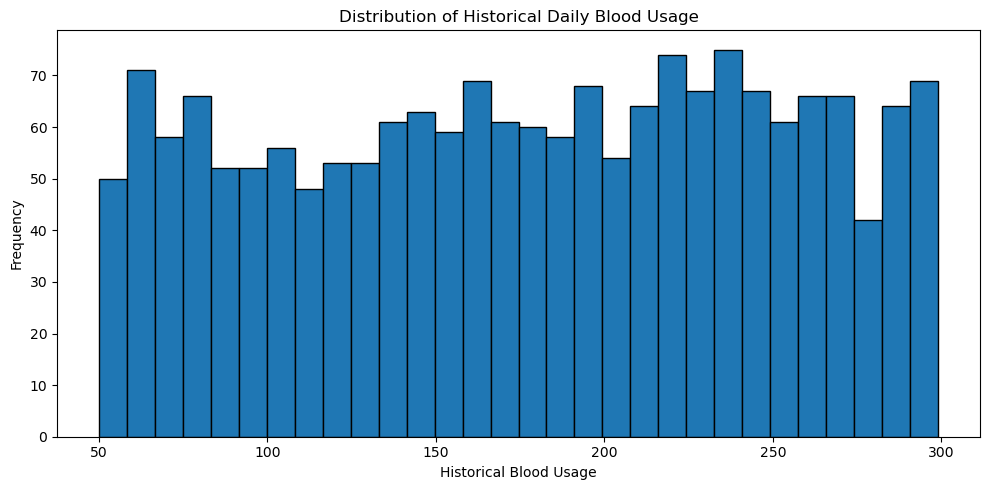

count    1827.000000
mean      177.652436
std        71.575611
min        50.000000
25%       117.000000
50%       180.000000
75%       238.000000
max       299.000000
Name: HistoricalBloodUsage, dtype: float64


In [24]:
blood_usage = pd.to_numeric(blood["HistoricalBloodUsage"], errors="coerce").dropna()

plt.figure(figsize=(10, 5))
plt.hist(blood_usage, bins=30, edgecolor="black")
plt.title("Distribution of Historical Daily Blood Usage")
plt.xlabel("Historical Blood Usage")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

print(blood_usage.describe())


### 3.2 Daily blood usage over time

This time plot helps identify broad changes, short-term fluctuations, and possible unusual observations. A visual pattern alone is not proof of seasonality or a causal explanation.


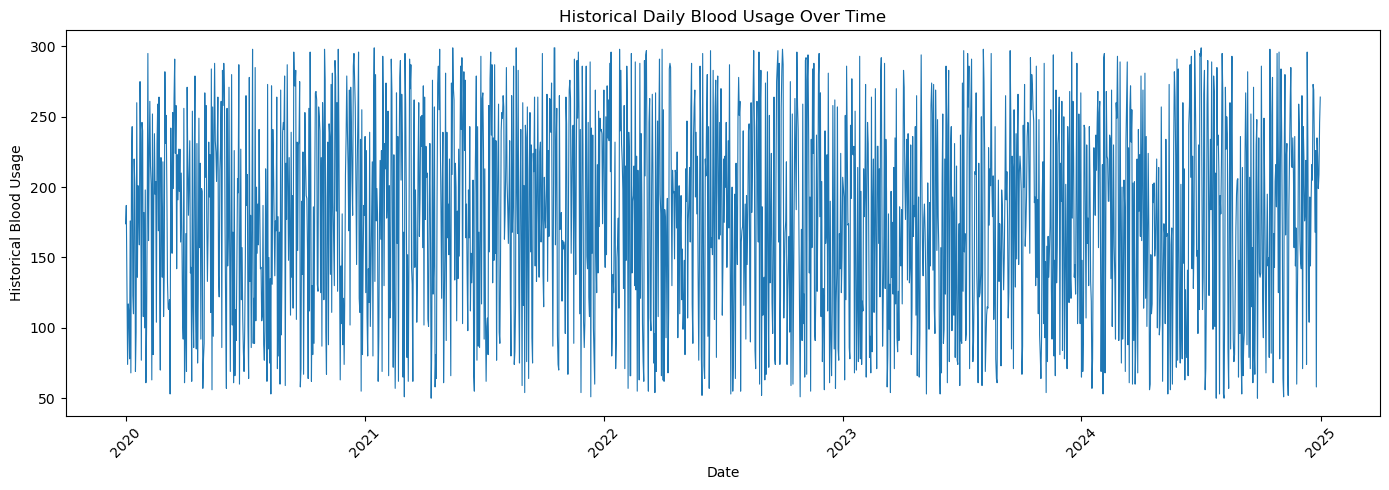

In [25]:
blood_time = blood.dropna(subset=["Date", "HistoricalBloodUsage"]).sort_values("Date")

plt.figure(figsize=(14, 5))
plt.plot(blood_time["Date"], blood_time["HistoricalBloodUsage"], linewidth=0.8)
plt.title("Historical Daily Blood Usage Over Time")
plt.xlabel("Date")
plt.ylabel("Historical Blood Usage")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### 3.3 Seven-day moving average

A seven-day rolling mean smooths some day-to-day variation. The first six rows are missing a rolling mean because seven observations are needed for the first complete window.


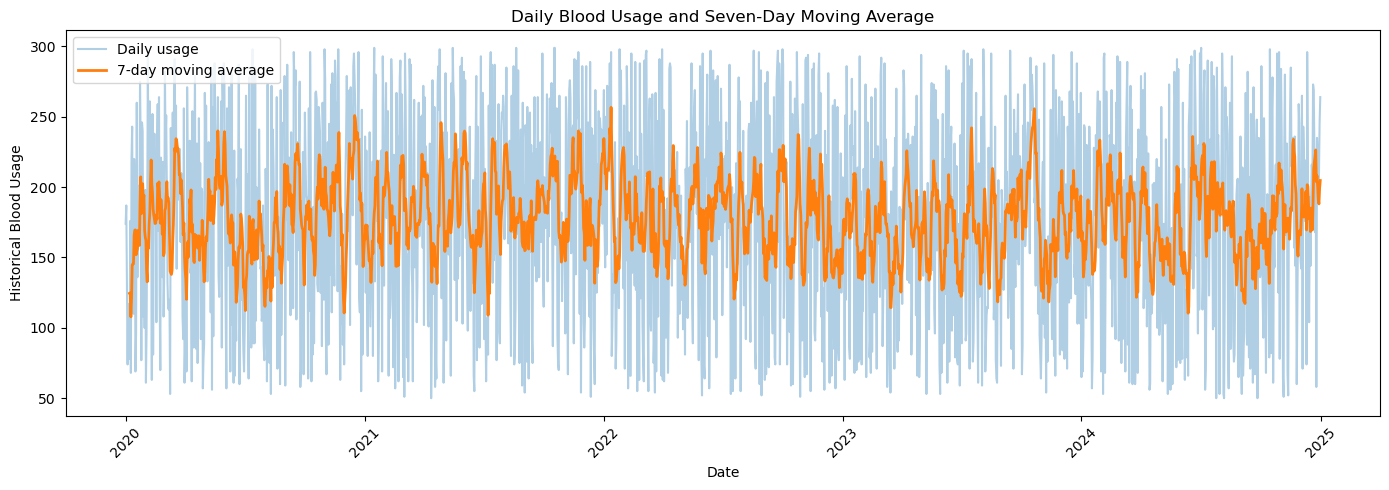

In [26]:
blood_time = blood_time.copy()
blood_time["7_Day_Moving_Average"] = (
    blood_time["HistoricalBloodUsage"].rolling(window=7, min_periods=7).mean()
)

plt.figure(figsize=(14, 5))
plt.plot(
    blood_time["Date"], blood_time["HistoricalBloodUsage"],
    alpha=0.35, label="Daily usage"
)
plt.plot(
    blood_time["Date"], blood_time["7_Day_Moving_Average"],
    linewidth=2, label="7-day moving average"
)
plt.title("Daily Blood Usage and Seven-Day Moving Average")
plt.xlabel("Date")
plt.ylabel("Historical Blood Usage")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### 3.4 Monthly average daily blood usage

Monthly totals can vary simply because months contain different numbers of days. For the main monthly analysis, use the **average daily usage within each month** rather than the sum. This makes the monthly values more comparable across months.

The monthly mean is an aggregation choice for analysis; the forecasting notebook must use the same definition consistently for training, testing, and forecasting.


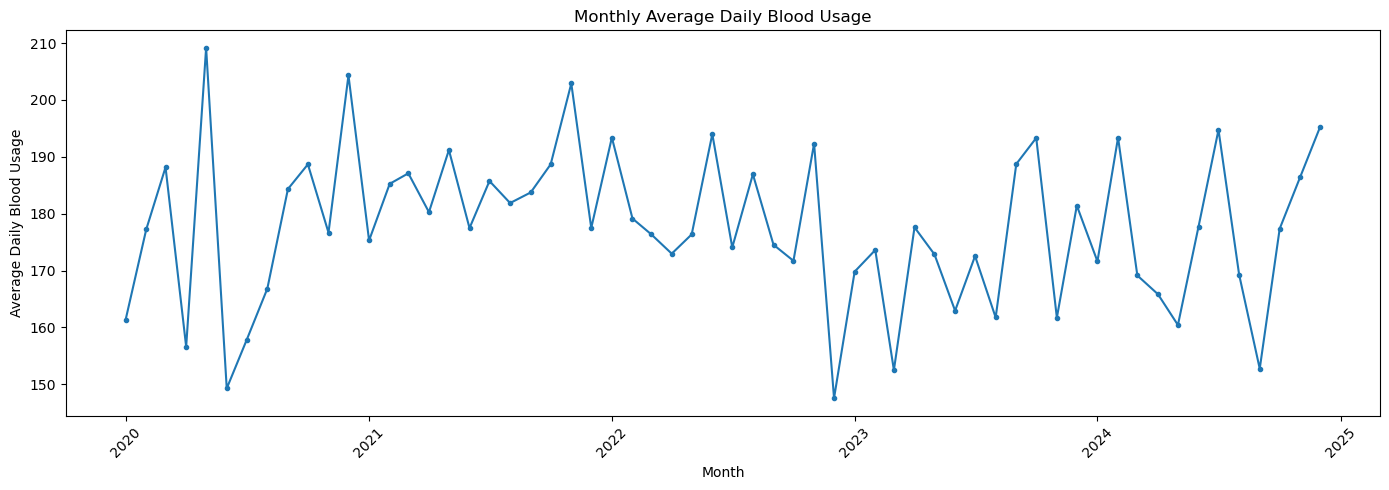

Number of monthly observations: 60
Monthly series range: 2020-01-01 00:00:00 to 2024-12-01 00:00:00


In [27]:
monthly_blood = (
    blood.dropna(subset=["Date", "HistoricalBloodUsage"])
    .set_index("Date")["HistoricalBloodUsage"]
    .resample("MS")
    .mean()
    .dropna()
)
monthly_blood.name = "MeanDailyBloodUsage"

plt.figure(figsize=(14, 5))
plt.plot(monthly_blood.index, monthly_blood.values, marker="o", markersize=3)
plt.title("Monthly Average Daily Blood Usage")
plt.xlabel("Month")
plt.ylabel("Average Daily Blood Usage")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Number of monthly observations:", len(monthly_blood))
print("Monthly series range:", monthly_blood.index.min(), "to", monthly_blood.index.max())


### 3.5 Decomposition into trend, seasonal, and residual components

A classical monthly decomposition is only useful when there are enough regular observations and a meaningful seasonal period can be justified. Here, the dataset has approximately five years of monthly observations, but it is synthetic and may not contain designed seasonality. The decomposition is therefore exploratory, not proof that a real seasonal process exists.


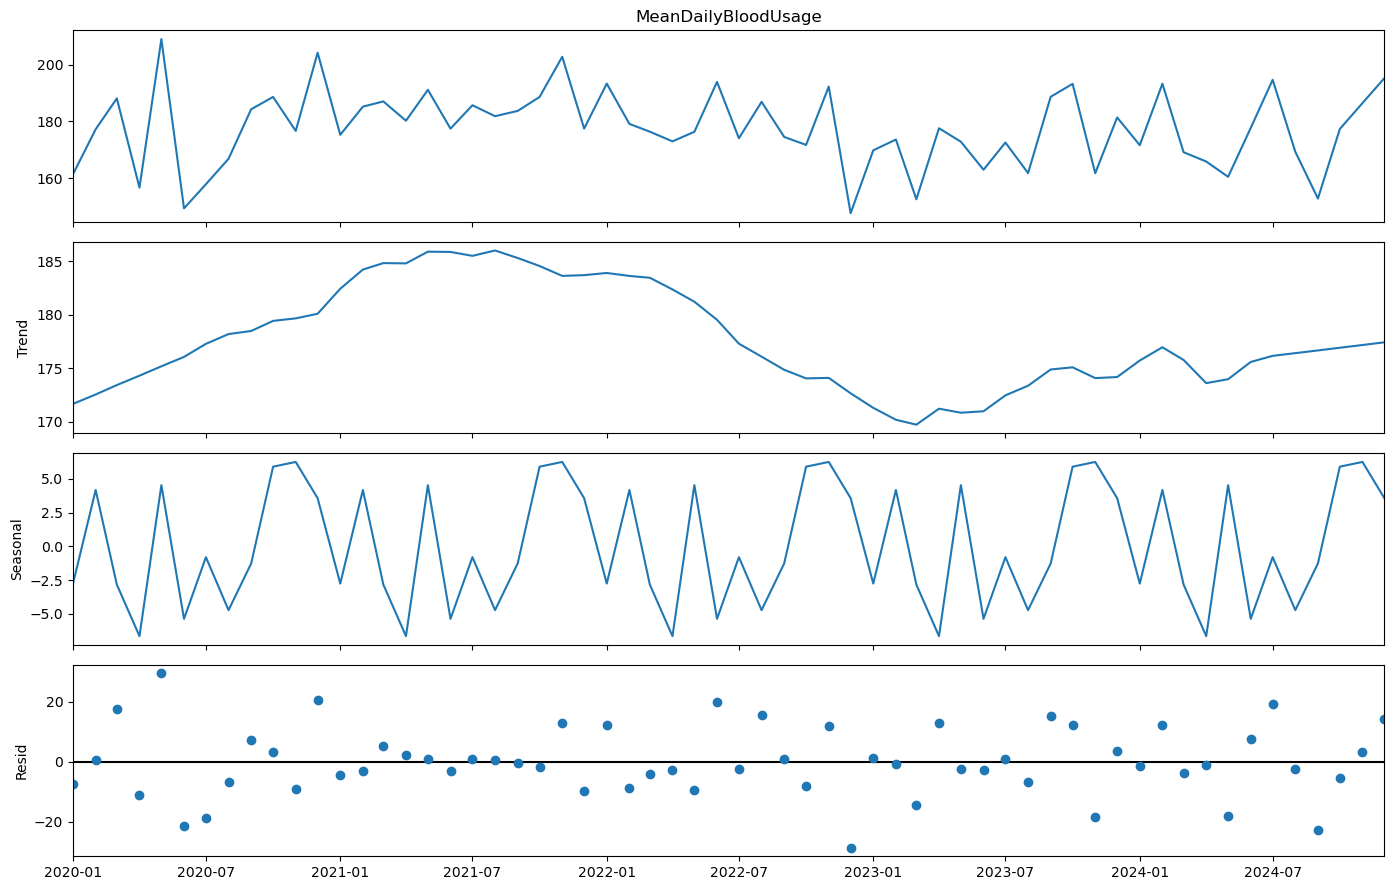

In [28]:
from statsmodels.tsa.seasonal import seasonal_decompose

if len(monthly_blood) >= 24 and monthly_blood.index.is_monotonic_increasing:
    decomposition = seasonal_decompose(
        monthly_blood,
        model="additive",
        period=12,
        extrapolate_trend="freq"
    )
    fig = decomposition.plot()
    fig.set_size_inches(14, 9)
    plt.tight_layout()
    plt.show()
else:
    print("Decomposition skipped: at least 24 regular monthly observations are required.")


## 4. Preliminary stationarity checks for blood demand

The Augmented Dickey–Fuller (ADF) test has a unit-root null hypothesis. The KPSS test has a stationarity null hypothesis. Reading them together is more informative than relying on ADF alone, particularly with a short series.

- **ADF p-value ≤ 0.05:** evidence against a unit root.
- **KPSS p-value ≤ 0.05:** evidence against level stationarity.
- Results are not definitive, especially with only about 60 monthly observations and synthetic data.


In [29]:
def stationarity_report(series, label):
    series = pd.Series(series).dropna().astype(float)
    print(f"\n{label} (n={len(series)})")
    if len(series) < 10 or series.nunique() < 2:
        print("Insufficient variation or observations for a useful stationarity test.")
        return

    adf_result = adfuller(series, autolag="AIC")
    print(f"ADF statistic: {adf_result[0]:.4f}")
    print(f"ADF p-value:   {adf_result[1]:.4f}")

    kpss_result = None
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            kpss_result = kpss(series, regression="c", nlags="auto")
        print(f"KPSS statistic: {kpss_result[0]:.4f}")
        print(f"KPSS p-value:   {kpss_result[1]:.4f}")
    except (ValueError, np.linalg.LinAlgError) as exc:
        print("KPSS could not be calculated:", exc)

    if adf_result[1] <= 0.05:
        print("ADF interpretation: reject the unit-root null at the 5% level.")
    else:
        print("ADF interpretation: do not reject the unit-root null at the 5% level.")

    if kpss_result is not None:
        if kpss_result[1] <= 0.05:
            print("KPSS interpretation: reject level stationarity at the 5% level.")
        else:
            print("KPSS interpretation: do not reject level stationarity at the 5% level.")

stationarity_report(monthly_blood, "Monthly average daily blood usage — level")



Monthly average daily blood usage — level (n=60)
ADF statistic: -1.9591
ADF p-value:   0.3048
KPSS statistic: 0.2531
KPSS p-value:   0.1000
ADF interpretation: do not reject the unit-root null at the 5% level.
KPSS interpretation: do not reject level stationarity at the 5% level.


### 4.1 First-order differencing

First-order differencing measures month-to-month change. It can help make a series stationary, but differencing should not be applied automatically: the model-selection notebook should compare plausible specifications and avoid unnecessary differencing.


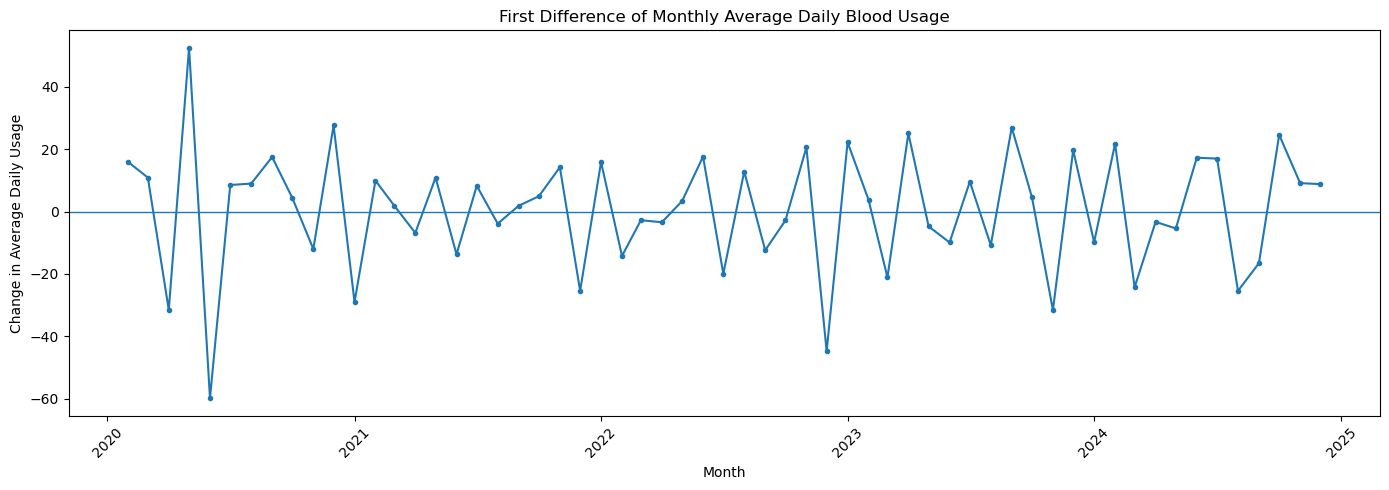


First-differenced monthly average daily blood usage (n=59)
ADF statistic: -7.8944
ADF p-value:   0.0000
KPSS statistic: 0.1900
KPSS p-value:   0.1000
ADF interpretation: reject the unit-root null at the 5% level.
KPSS interpretation: do not reject level stationarity at the 5% level.


In [30]:
monthly_blood_diff = monthly_blood.diff().dropna()

plt.figure(figsize=(14, 5))
plt.plot(monthly_blood_diff.index, monthly_blood_diff.values, marker="o", markersize=3)
plt.axhline(0, linewidth=1)
plt.title("First Difference of Monthly Average Daily Blood Usage")
plt.xlabel("Month")
plt.ylabel("Change in Average Daily Usage")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

stationarity_report(monthly_blood_diff, "First-differenced monthly average daily blood usage")


### 4.2 ACF and PACF of the differenced series

The autocorrelation function (ACF) and partial autocorrelation function (PACF) show sample dependence at different lags. They can inform candidate model specifications, but they do not determine ARIMA orders on their own. With a short series, individual spikes can occur by chance.


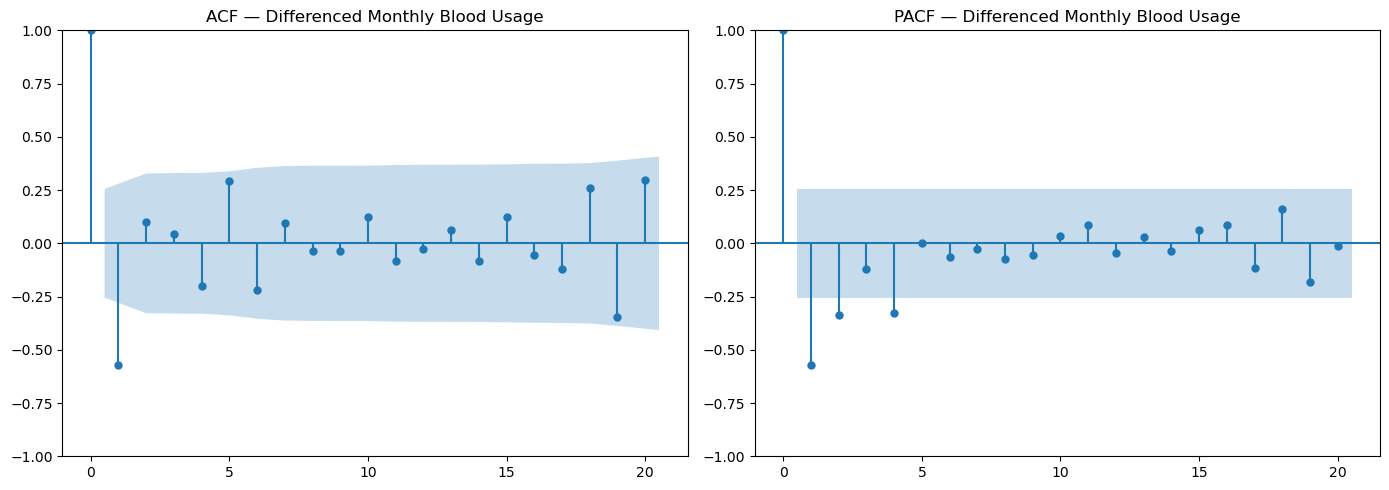

In [31]:
if len(monthly_blood_diff) >= 10:
    max_lags = min(20, len(monthly_blood_diff) // 2 - 1)
    if max_lags >= 1:
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        plot_acf(monthly_blood_diff, ax=axes[0], lags=max_lags)
        axes[0].set_title("ACF — Differenced Monthly Blood Usage")
        plot_pacf(monthly_blood_diff, ax=axes[1], lags=max_lags, method="ywm")
        axes[1].set_title("PACF — Differenced Monthly Blood Usage")
        plt.tight_layout()
        plt.show()
    else:
        print("Not enough observations to plot ACF/PACF.")
else:
    print("Not enough observations to plot ACF/PACF.")


## 5. Pharmaceutical-sales exploratory analysis

The pharmaceutical dataset contains multiple ATC sales groups. `datum` is used as the date field; helper columns such as `Hour` should not be treated as sales measures. The analysis below identifies the available sales columns rather than assuming every numeric column is a medicine category.


In [32]:
print("Pharmaceutical columns:")
print(pharma.columns.tolist())

# Known ATC sales groups in the supplied project dataset.
expected_atc = ["M01AB", "M01AE", "N02BA", "N02BE", "N05B", "N05C", "R03", "R06"]
atc_columns = [column for column in expected_atc if column in pharma.columns]

if not atc_columns:
    print("No expected ATC columns found. Review the column names above before proceeding.")
else:
    print("ATC sales columns included in the analysis:", atc_columns)
    display(pharma[atc_columns].describe().T)


Pharmaceutical columns:
['datum', 'Year', 'Month', 'Weekday Name', 'M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03', 'R06']
ATC sales columns included in the analysis: ['M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03', 'R06']


,count,mean,std,min,25%,50%,75%,max
M01AB,2106.0,5.033683,2.737579,0.0,3.00,4.99,6.670,17.340000
M01AE,2106.0,3.895830,2.133337,0.0,2.34,3.67,5.138,14.463000
N02BA,2106.0,3.880441,2.384010,0.0,2.00,3.50,5.200,16.000000
N02BE,2106.0,29.917095,15.590966,0.0,19.00,26.90,38.300,161.000000
N05B,2106.0,8.853627,5.605605,0.0,5.00,8.00,12.000,54.833333
N05C,2106.0,0.593522,1.092988,0.0,0.00,0.00,1.000,9.000000
R03,2106.0,5.512262,6.428736,0.0,1.00,4.00,8.000,45.000000
R06,2106.0,2.900198,2.415816,0.0,1.00,2.00,4.000,15.000000


### 5.1 Missing values, zeros, and negative values by ATC group

Zero sales can be meaningful, particularly for intermittent-demand products. They should not automatically be treated as missing values. Negative values should be investigated in context rather than silently removed.


In [33]:
if atc_columns:
    quality_summary = pd.DataFrame({
        "missing_values": pharma[atc_columns].isna().sum(),
        "zero_values": (pharma[atc_columns] == 0).sum(),
        "negative_values": (pharma[atc_columns] < 0).sum(),
        "nonzero_observations": (pharma[atc_columns] != 0).sum()
    })
    display(quality_summary)


,missing_values,zero_values,negative_values,nonzero_observations
M01AB,0,40,0,2066
M01AE,0,36,0,2070
N02BA,0,78,0,2028
N02BE,0,26,0,2080
N05B,0,43,0,2063
N05C,0,1430,0,676
R03,0,484,0,1622
R06,0,256,0,1850


### 5.2 Distribution of daily sales by ATC group

The boxplots compare scale and spread across sales groups. Differences in scale may make direct visual comparison difficult; the plots are descriptive and do not establish which product group is more important clinically.


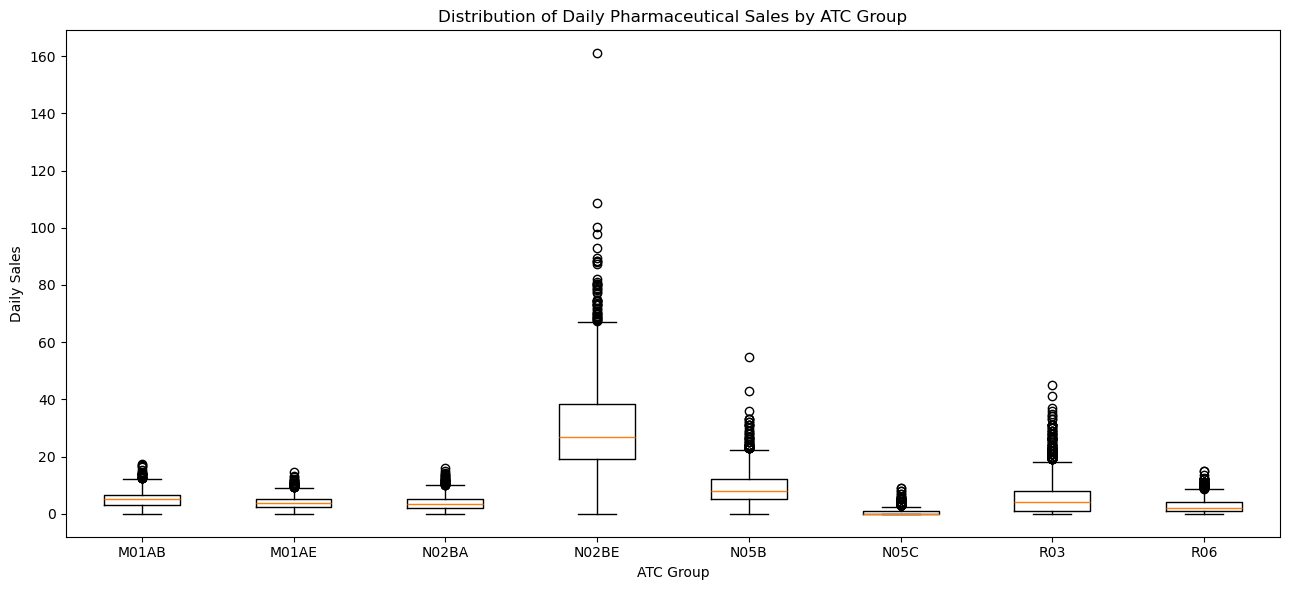

In [34]:
if atc_columns:
    pharma_values = pharma[atc_columns].apply(pd.to_numeric, errors="coerce")
    plt.figure(figsize=(13, 6))
    plt.boxplot(
        [pharma_values[column].dropna().values for column in atc_columns],
        tick_labels=atc_columns,
        showfliers=True
    )
    plt.title("Distribution of Daily Pharmaceutical Sales by ATC Group")
    plt.xlabel("ATC Group")
    plt.ylabel("Daily Sales")
    plt.tight_layout()
    plt.show()


### 5.3 Pharmaceutical sales over time

Daily data may be noisy, so monthly averages are used here to show broad changes while keeping months comparable. These summaries are exploratory; the forecasting notebook should evaluate each ATC series separately and include methods suited to intermittent demand.


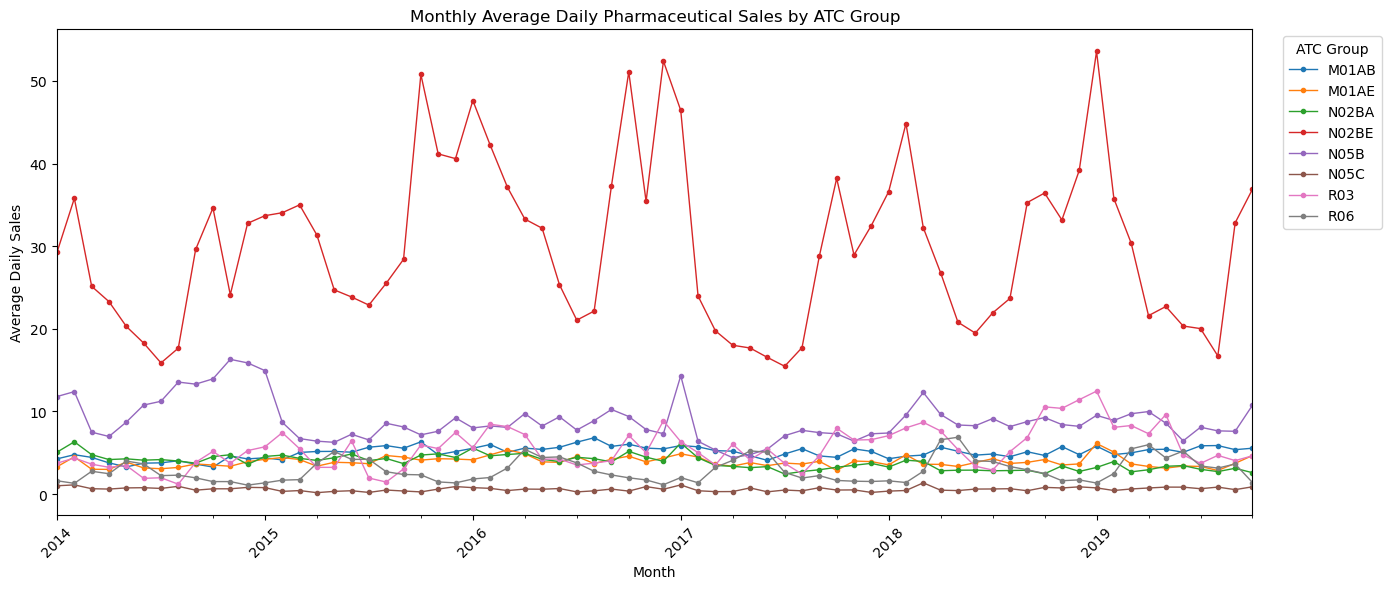

,count,mean,std,min,25%,50%,75%,max
M01AB,70.0,5.037697,0.734473,3.264355,4.604750,5.130602,5.551813,6.810645
M01AE,70.0,3.907882,0.614878,2.847387,3.510138,3.821259,4.264623,6.117613
N02BA,70.0,3.872008,0.868946,2.425806,3.197984,3.940438,4.441129,6.321429
N02BE,70.0,30.011014,9.736935,15.462903,21.971237,29.430833,35.776000,53.568129
N05B,70.0,8.873562,2.503719,4.400000,7.322581,8.254023,9.617857,16.300000
N05C,70.0,0.596044,0.241129,0.166667,0.404839,0.600000,0.760484,1.354839
R03,70.0,5.508174,2.427728,1.193548,3.715591,5.145161,7.174194,12.451613
R06,70.0,2.879347,1.444999,1.077419,1.653514,2.468656,3.898629,6.872258


In [35]:
if atc_columns:
    pharma_time = pharma.dropna(subset=["datum"]).sort_values("datum").copy()
    pharma_time[atc_columns] = pharma_time[atc_columns].apply(pd.to_numeric, errors="coerce")
    monthly_pharma_mean = pharma_time.set_index("datum")[atc_columns].resample("MS").mean()
    monthly_pharma_mean = monthly_pharma_mean.dropna(how="all")

    if monthly_pharma_mean.empty:
        print("Monthly pharmaceutical plot skipped: no valid numeric sales values were available.")
    else:
        fig, ax = plt.subplots(figsize=(14, 6))
        monthly_pharma_mean.plot(ax=ax, marker=".", linewidth=1)
        ax.set_title("Monthly Average Daily Pharmaceutical Sales by ATC Group")
        ax.set_xlabel("Month")
        ax.set_ylabel("Average Daily Sales")
        ax.legend(title="ATC Group", bbox_to_anchor=(1.02, 1), loc="upper left")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()
        display(monthly_pharma_mean.describe().T)
else:
    print("Pharmaceutical time-series plots skipped because no expected ATC sales columns were found.")

### 5.4 Intermittent-demand profile

The proportion of zero observations helps identify sales groups where Croston-type methods may be worth evaluating. This is a screening step, not a model-selection decision by itself.


In [36]:
if atc_columns:
    zero_profile = pd.DataFrame({
        "observations": pharma[atc_columns].notna().sum(),
        "zero_count": (pharma[atc_columns] == 0).sum(),
        "zero_percentage": (pharma[atc_columns] == 0).mean().mul(100).round(2),
        "positive_count": (pharma[atc_columns] > 0).sum(),
        "negative_count": (pharma[atc_columns] < 0).sum()
    })
    display(zero_profile.sort_values("zero_percentage", ascending=False))


,observations,zero_count,zero_percentage,positive_count,negative_count
N05C,2106,1430,67.90,676,0
R03,2106,484,22.98,1622,0
R06,2106,256,12.16,1850,0
N02BA,2106,78,3.70,2028,0
N05B,2106,43,2.04,2063,0
M01AB,2106,40,1.90,2066,0
M01AE,2106,36,1.71,2070,0
N02BE,2106,26,1.23,2080,0


## 6. EDA findings and implications for modelling

The blood-demand series contains 1,827 daily observations spanning 1 January 2020 to 31 December 2024. The monthly series contains 60 observations. In the level-series stationarity checks, ADF p = 0.30 does not reject its unit-root null, while KPSS p = 0.10 does not reject its stationarity null at the 5% level. These tests therefore provide **inconclusive, conflicting evidence**; neither result alone justifies a definitive claim about stationarity. The first-differenced series should be inspected alongside the plots and autocorrelation functions before choosing a model.

The pharmaceutical data contain 2,106 daily records from 2 January 2014 through 8 October 2019. October 2019 is incomplete and should be excluded from monthly model evaluation. Use monthly **means of daily sales**, not monthly sums, when comparing calendar months of different lengths. Missing calendar dates must not automatically be filled with zero because a missing row does not necessarily mean zero demand.

Zero-sales profiles indicate that demand is intermittent for some groups, especially N05C, R03 and R06. Croston-type methods should be assessed on daily or weekly observations for these groups rather than on monthly totals. The reported proportions and summary statistics in the tables above should be used as the source of exact group-level findings.

The blood dataset is synthetic, so results demonstrate a forecasting workflow rather than validated hospital demand. Model selection should use consistent out-of-sample evaluation, simple baselines, and uncertainty-aware interpretation. Do not claim seasonality or a model advantage unless supported by the plots and evaluation outputs.